# Assignment: Data Wrangling

### Reading material: `tidy_data.pdf`

**Q1.** This question provides some practice cleaning variables which have common problems.
1. For `./data/airbnb_hw.csv`, clean the `Price` variable as well as you can, and explain the choices you make. How many missing values do you end up with? (Hint: What happens to the formatting when a price goes over 999 dollars, say from 675 to 1,112?)
2. For the Minnesota police use of for data, `./data/mn_police_use_of_force.csv`, clean the `subject_injury` variable, handling the NA's; this gives a value `Yes` when a person was injured by police, and `No` when no injury occurred. What proportion of the values are missing? Is this a concern? Cross-tabulate your cleaned `subject_injury` variable with the `force_type` variable. Are there any patterns regarding when the data are missing?

**Q2.** Go to https://sharkattackfile.net/ and download their dataset on shark attacks (Hint: `GSAF5.xls`).

1. Open the shark attack file using Pandas. It is probably not a csv file, so `read_csv` won't work.
2. Drop any columns that do not contain data.
3. Clean the year variable. Describe the range of values you see. Filter the rows to focus on attacks since 1940. Are attacks increasing, decreasing, or remaining constant over time?
4. Clean the Age variable and make a histogram of the ages of the victims.
5. What proportion of victims are male?
6. Clean the `Type` variable so it only takes three values: Provoked and Unprovoked and Unknown. What proportion of attacks are unprovoked?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Matthew Calvario

**Date:** 09/02/26

In [1]:
# Your Phase 1 solution to the problem goes here.
!git clone https://github.com/Matthew-Calvario/A01-data-wrangling.git


Cloning into 'A01-data-wrangling'...
remote: Enumerating objects: 27, done.
remote: Counting objects: 100% (13/13), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 27 (delta 10), reused 5 (delta 5), pack-reused 14 (from 1)
Receiving objects: 100% (27/27), 3.43 MiB | 7.25 MiB/s, done.
Resolving deltas: 100% (10/10), done.


In [93]:
import pandas as pd
import matplotlib as plt
import numpy as np

# Question 1.1.

df = pd.read_csv('A01-data-wrangling/data/airbnb_hw.csv')

print((df["Price"]).shape)
print((df["Price"]).describe())
print((df["Price"]).isna().sum())
print((df["Price"]==0).sum())
print(df["Price"].isna().sum())
print(df["Price"].head())

print(df["Price"].unique())

# When values of price are greater than 999, they include a comma since that is
# the convention for writing dollar values passed the 1000 mark. However, for
# purpose of data analysis, I will remove commas from values greater than 999
# and then convert all figures to numeric for easier manipulation and replicable data consistency.

df['Price_clean'] = df['Price'].str.replace(",", "", regex=False)
print(df['Price_clean'].head())

# To show the difference, I will make it into a new column called 'Price_numeric'
df['Price_numeric'] = pd.to_numeric(df['Price_clean'], errors = "coerce")
print((df["Price_numeric"] >= 1000).sum())
print(df['Price_numeric'].unique())


(30478,)
count     30478
unique      511
top         150
freq       1481
Name: Price, dtype: object
0
0
0
0    145
1     37
2     28
3    199
4    549
Name: Price, dtype: object
['145' '37' '28' '199' '549' '149' '250' '90' '270' '290' '170' '59' '49'
 '68' '285' '75' '100' '150' '700' '125' '175' '40' '89' '95' '99' '499'
 '120' '79' '110' '180' '143' '230' '350' '135' '85' '60' '70' '55' '44'
 '200' '165' '115' '74' '84' '129' '50' '185' '80' '190' '140' '45' '65'
 '225' '600' '109' '1,990' '73' '240' '72' '105' '155' '160' '42' '132'
 '117' '295' '280' '159' '107' '69' '239' '220' '399' '130' '375' '585'
 '275' '139' '260' '35' '133' '300' '289' '179' '98' '195' '29' '27' '39'
 '249' '192' '142' '169' '1,000' '131' '138' '113' '122' '329' '101' '475'
 '238' '272' '308' '126' '235' '315' '248' '128' '56' '207' '450' '215'
 '210' '385' '445' '136' '247' '118' '77' '76' '92' '198' '205' '299'
 '222' '245' '104' '153' '349' '114' '320' '292' '226' '420' '500' '325'
 '307' '78' '265' '10

In [95]:
# Question 1.2

df_police = pd.read_csv('A01-data-wrangling/data/mn_police_use_of_force.csv')

print((df_police["subject_injury"]).shape)
print((df_police["subject_injury"]).unique())

df_police['subject_injury_missing'] =(df_police["subject_injury"]).isna()
print(df_police['subject_injury_missing'])

subject_injury_missing_proportion = (df_police["subject_injury"].isna().sum()) / (df_police["subject_injury"].shape[0])
print(f"The percentage of nan values in the subject injury variable is {subject_injury_missing_proportion:.2f}. This is a significant majority of the count and may impede empirical observation of the true subject injury proportion.")

# Cross-tabulating subject injuries and force type

print(pd.crosstab(df_police['subject_injury_missing'],df_police['force_type']))

# Based on the cross-tabulation results, it appears that options that use relatively
# pronounced force--bodily force, chemical irritants, and maxmial restraint technique--
# have high proportions of missing values. These could be systematic omissions, whether
# intentionally or not, that require additional scrutiny in order to eliminate bias or false conclusions
# about injury causes from force types.





(12925,)
[nan 'No' 'Yes']
0        True
1        True
2        True
3        True
4        True
         ... 
12920    True
12921    True
12922    True
12923    True
12924    True
Name: subject_injury_missing, Length: 12925, dtype: bool
The percentage of nan values in the subject injury variable is 0.76. This is a significant majority of the count and may impede empirical observation of the true subject injury proportion.
force_type              Baton  Bodily Force  Chemical Irritant  Firearm  \
subject_injury_missing                                                    
False                       2          2379                172        2   
True                        2          7051               1421        0   

force_type              Gun Point Display  Improvised Weapon  Less Lethal  \
subject_injury_missing                                                      
False                                  77                 74            0   
True                                   27 

In [106]:
# Question 2.

df_shark = pd.read_excel('A01-data-wrangling/data/GSAF5.xls')

# 2.2 Drop columns with no data

print(df_shark.columns)
print(df_shark.count())
for col in df_shark.columns:
  print(f'Column name: {col}; Null values: {df_shark[col].isnull().sum()}')

df_shark.drop(columns=['Unnamed: 21','Unnamed: 22'], axis=1)

# 2.3 Clean year

print(df_shark['Year'].head())
print(f'Number of rows in Year: {len(df_shark['Year'])}')
print(f'Number of NaN values in Year: {df_shark['Year'].isna().sum()}')

# Remove/impute NaN values

df_shark = df_shark.dropna(subset=['Year'])

# Double check
print(f'Number of NaN values in Year: {df_shark['Year'].isna().sum()}')

# Year is a float; convert to integer and then check
df_shark['Year'] = df_shark['Year'].astype(int)
print(df_shark['Year'].head())

# Look at the range of values for years
print(f'Latest year: {df_shark['Year'].min()}')
print(f'Earliest Year: {df_shark['Year'].max()}')

print(df_shark['Year'].unique())

# Remove impossible values and check

df_shark = df_shark[df_shark['Year'] >= 1500]
print(df_shark['Year'].unique())

# Since the 1940s

Year_range_1 = df_shark[(df_shark['Year'] >= 1940) & (df_shark['Year'] < 1950)]
Year_range_2 = df_shark[(df_shark['Year'] >= 1950) & (df_shark['Year'] < 1960)]
Year_range_3 = df_shark[(df_shark['Year'] >= 1960) & (df_shark['Year'] < 1970)]
Year_range_4 = df_shark[(df_shark['Year'] >= 1970) & (df_shark['Year'] < 1980)]
Year_range_5 = df_shark[(df_shark['Year'] >= 1980) & (df_shark['Year'] < 1990)]
Year_range_6 = df_shark[(df_shark['Year'] >= 1990) & (df_shark['Year'] < 2000)]
Year_range_7 = df_shark[(df_shark['Year'] >= 2000) & (df_shark['Year'] < 2010)]
Year_range_8 = df_shark[(df_shark['Year'] >= 2010) & (df_shark['Year'] < 2020)]
Year_range_9 = df_shark[(df_shark['Year'] >= 2020) & (df_shark['Year'] < 2026)]

print(len(Year_range_1))
print(len(Year_range_2))
print(len(Year_range_3))
print(len(Year_range_4))
print(len(Year_range_5))
print(len(Year_range_6))
print(len(Year_range_7))
print(len(Year_range_8))
print(len(Year_range_9))

# Shark attacks appear to be increasing every decade since the 1940s;
# 2020-2026 is not complete but looks to follow the trend or at least remain
# similar to the previous decade.





Index(['Date', 'Year', 'Type', 'Country', 'State', 'Location', 'Activity',
       'Name', 'Sex', 'Age', 'Injury', 'Fatal Y/N', 'Time', 'Species ',
       'Source', 'pdf', 'href formula', 'href', 'Case Number', 'Case Number.1',
       'original order', 'Unnamed: 21', 'Unnamed: 22'],
      dtype='object')
Date              7117
Year              7115
Type              7099
Country           7067
State             6630
Location          6550
Activity          6534
Name              6899
Sex               6539
Age               4123
Injury            7081
Fatal Y/N         6556
Time              3590
Species           3986
Source            7097
pdf               6799
href formula      6794
href              6796
Case Number       6798
Case Number.1     6797
original order    6799
Unnamed: 21          1
Unnamed: 22          2
dtype: int64
Column name: Date; Null values: 0
Column name: Year; Null values: 2
Column name: Type; Null values: 18
Column name: Country; Null values: 50
Column name:

0     ?
1    43
2     ?
3    27
4    71
Name: Age, dtype: object
6983
Number of missing age values: 2876
158
240
245
127
164
171
259
310
['?' '43' '27' '71' '21' '69' '31' '13' '12' '17' '35' "20's" '19' '11'
 '20' '38' '39' '16' '22' '30+' "50's" '55' '26' '56' '24' '25' '61' '40'
 '14' '50+' '54' '48' '57' '8' '63' '9' '7' '85' '18' '66' '37' '42' '45'
 '30' '60' '40+' '29' 35 58 29 24 20 55 17 12 37 36 23 40 28 69 48 '60+'
 57 45 61 27 38 16 68 33 30 15 41 14 43 26 'Middle age' 18 21 49 25 46 19
 65 64 nan '46' '32' '10' '64' '62' '15' '52' '44' '47' '59' '50' '34'
 '30s' '20/30' '65' '20s' '77' '49' '!2' '73' '50s' '58' '67' '6' '41'
 '53' '68' '51' 39 51 10 13 60 '40s' 62 'teen' 8 22 32 56 'Teen' 42 50 'M'
 9 31 11 34 '!6' '!!' 47 7 71 59 53 54 75 '45 and 15' 73 52 70 4 63 44
 '28 & 22' '22, 57, 31' '60s' 67 74 '9 & 60' 'a minor' 6 3 82 '40?' 66 72
 '23' '36' '70' '18 months' '28' '33' '74' '3' '28 & 26' '5' '86'
 '18 or 20' '12 or 13' '46 & 34' '28, 23 & 30' 'Teens' 77 '36 & 26'


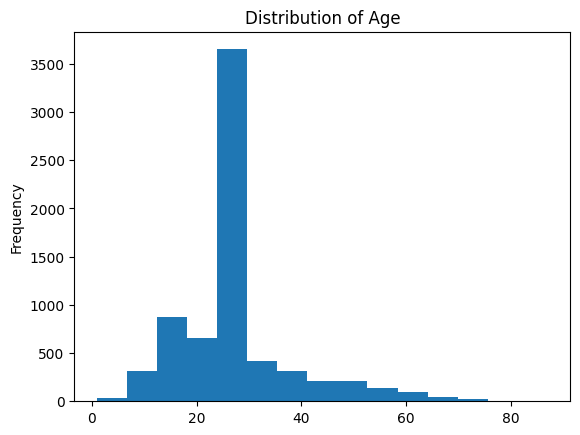

In [107]:
import matplotlib.pyplot as plt

# 2.4 Clean Age variable

print(df_shark['Age'].head())
print(len(df_shark['Age']))
print(f'Number of missing age values: {df_shark['Age'].isna().sum()}')

# Check if Age variable has concentrated areas of missing values

print(Year_range_1['Age'].isna().sum())
print(Year_range_2['Age'].isna().sum())
print(Year_range_3['Age'].isna().sum())
print(Year_range_4['Age'].isna().sum())
print(Year_range_5['Age'].isna().sum())
print(Year_range_6['Age'].isna().sum())
print(Year_range_7['Age'].isna().sum())
print(Year_range_8['Age'].isna().sum())

# Missingness seems to be proportial to amount missing per decade, so no concentrated areas

# For phase 1, replace all weirdly formatted options with NaNs, then proceed with median imputation
print(df_shark['Age'].unique())
df_shark['Age_clean'] = pd.to_numeric(df_shark['Age'], errors='coerce')
print(df_shark['Age_clean'].isna().sum())
df_shark['Age_clean'] = df_shark['Age_clean'].fillna(
    df_shark['Age_clean'].median()
)

df_shark['Age_clean'].plot(kind='hist', bins=15)
plt.title('Distribution of Age')
plt.show()

In [108]:
# 2.5 Proportion that are male

proportion_male_victims = (len(df_shark[df_shark['Sex']=='M'])/ len(df_shark))
print(f'The proportion of victims that were male in this dataset is: {proportion_male_victims}')

The proportion of victims that were male in this dataset is: 0.8006587426607475


In [109]:
# 2.6 Provoked, unprovoked, and unkwown

df_shark['Type'].unique()

for row in df_shark['Type']:

  if row not in ['Unprovoked','Provoked','Unknown']:
    df_shark['Type'] = df_shark['Type'].replace(row, '')

# Double check
print(df_shark['Type'].unique())
print(df_shark['Type'].head(20))

# Find proportion that is unprovoked

proportion_unprovoked = (len(df_shark[df_shark['Type']=='Unprovoked'])) / (len(df_shark['Type']))
print(f'The proportion of types of attacks that were unprovoked is {proportion_unprovoked}.')

['Unprovoked' 'Provoked' '']
0     Unprovoked
1     Unprovoked
2       Provoked
3       Provoked
4     Unprovoked
5     Unprovoked
6     Unprovoked
7     Unprovoked
8     Unprovoked
9     Unprovoked
10    Unprovoked
11    Unprovoked
12      Provoked
13    Unprovoked
14    Unprovoked
15    Unprovoked
16    Unprovoked
17    Unprovoked
18    Unprovoked
19      Provoked
Name: Type, dtype: object
The proportion of types of attacks that were unprovoked is 0.7370757554059859.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]